<a href="https://colab.research.google.com/github/3OMDEH/Machine-Learning-Projects-Beginner-/blob/main/AirQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# **Reading the Data**

In [111]:
#@title .
#!pip install ucimlrepo

In [112]:
#@title Path Reading and Splitting into x and y
df = pd.read_csv("/content/AirQualityUCI.csv", sep=';', decimal=',')
# All the values in the csv file are separated by ";",  and the numbers are separated by a commma.

x = df.drop('CO(GT)', axis=1)
y = df['CO(GT)']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [113]:
print(x_test.shape)
print(x_train.shape)

(1895, 16)
(7576, 16)


In [114]:
x.info() # Full Data Info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   PT08.S1(CO)    9357 non-null   float64
 3   NMHC(GT)       9357 non-null   float64
 4   C6H6(GT)       9357 non-null   float64
 5   PT08.S2(NMHC)  9357 non-null   float64
 6   NOx(GT)        9357 non-null   float64
 7   PT08.S3(NOx)   9357 non-null   float64
 8   NO2(GT)        9357 non-null   float64
 9   PT08.S4(NO2)   9357 non-null   float64
 10  PT08.S5(O3)    9357 non-null   float64
 11  T              9357 non-null   float64
 12  RH             9357 non-null   float64
 13  AH             9357 non-null   float64
 14  Unnamed: 15    0 non-null      float64
 15  Unnamed: 16    0 non-null      float64
dtypes: float64(14), object(2)
memory usage: 1.2+ MB


In [115]:
x.shape # Full Data Shape

(9471, 16)

In [116]:
x_train.info() # Training Features Info

<class 'pandas.core.frame.DataFrame'>
Index: 7576 entries, 7563 to 7270
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           7484 non-null   object 
 1   Time           7484 non-null   object 
 2   PT08.S1(CO)    7484 non-null   float64
 3   NMHC(GT)       7484 non-null   float64
 4   C6H6(GT)       7484 non-null   float64
 5   PT08.S2(NMHC)  7484 non-null   float64
 6   NOx(GT)        7484 non-null   float64
 7   PT08.S3(NOx)   7484 non-null   float64
 8   NO2(GT)        7484 non-null   float64
 9   PT08.S4(NO2)   7484 non-null   float64
 10  PT08.S5(O3)    7484 non-null   float64
 11  T              7484 non-null   float64
 12  RH             7484 non-null   float64
 13  AH             7484 non-null   float64
 14  Unnamed: 15    0 non-null      float64
 15  Unnamed: 16    0 non-null      float64
dtypes: float64(14), object(2)
memory usage: 1006.2+ KB


In [117]:
x_train.head(5)

,Date,Time,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
7563,19/01/2005,21.00.00,1016.0,-200.0,7.8,892.0,317.0,758.0,141.0,1109.0,945.0,9.2,49.8,0.5808,NaN,NaN
3991,24/08/2004,01.00.00,919.0,-200.0,5.7,799.0,29.0,844.0,50.0,1409.0,881.0,22.2,43.1,1.1396,NaN,NaN
5712,03/11/2004,18.00.00,1333.0,-200.0,20.5,1312.0,383.0,520.0,107.0,1853.0,1364.0,23.8,51.4,1.4956,NaN,NaN
472,30/03/2004,10.00.00,1565.0,735.0,21.0,1324.0,320.0,695.0,159.0,1872.0,1688.0,17.9,28.2,0.5741,NaN,NaN
4246,03/09/2004,16.00.00,1130.0,-200.0,13.9,1113.0,-200.0,674.0,-200.0,1623.0,1127.0,38.8,17.6,1.1979,NaN,NaN


The indexes are random, they are not arranged, we need to fix that

In [118]:
#@title Reset the index of x_train | x_test to a default integer index
x_train = x_train.reset_index(drop=True) # if we set the drop parameter to false, the current index of the dataframe will be converted into a new column
x_test = x_test.reset_index(drop=True) # if we set the drop parameter to false, the current index of the dataframe will be converted into a new column

# Display the first few rows to show the new index
display(x_train.head())

,Date,Time,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,19/01/2005,21.00.00,1016.0,-200.0,7.8,892.0,317.0,758.0,141.0,1109.0,945.0,9.2,49.8,0.5808,NaN,NaN
1,24/08/2004,01.00.00,919.0,-200.0,5.7,799.0,29.0,844.0,50.0,1409.0,881.0,22.2,43.1,1.1396,NaN,NaN
2,03/11/2004,18.00.00,1333.0,-200.0,20.5,1312.0,383.0,520.0,107.0,1853.0,1364.0,23.8,51.4,1.4956,NaN,NaN
3,30/03/2004,10.00.00,1565.0,735.0,21.0,1324.0,320.0,695.0,159.0,1872.0,1688.0,17.9,28.2,0.5741,NaN,NaN
4,03/09/2004,16.00.00,1130.0,-200.0,13.9,1113.0,-200.0,674.0,-200.0,1623.0,1127.0,38.8,17.6,1.1979,NaN,NaN


In [119]:
x_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1895 entries, 0 to 1894
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           1873 non-null   object 
 1   Time           1873 non-null   object 
 2   PT08.S1(CO)    1873 non-null   float64
 3   NMHC(GT)       1873 non-null   float64
 4   C6H6(GT)       1873 non-null   float64
 5   PT08.S2(NMHC)  1873 non-null   float64
 6   NOx(GT)        1873 non-null   float64
 7   PT08.S3(NOx)   1873 non-null   float64
 8   NO2(GT)        1873 non-null   float64
 9   PT08.S4(NO2)   1873 non-null   float64
 10  PT08.S5(O3)    1873 non-null   float64
 11  T              1873 non-null   float64
 12  RH             1873 non-null   float64
 13  AH             1873 non-null   float64
 14  Unnamed: 15    0 non-null      float64
 15  Unnamed: 16    0 non-null      float64
dtypes: float64(14), object(2)
memory usage: 237.0+ KB


In [120]:
#@title 'drop = false' <---Test
# Let's see what happens if we set drop=False
# First, create a sample DataFrame with a custom index
sample_df = pd.DataFrame({'A': [1, 2, 3]}, index=['a', 'b', 'c'])
print("Original DataFrame with custom index:")
display(sample_df)

# Reset index with drop=False
sample_df_reset_false = sample_df.reset_index(drop=False)
print("DataFrame after reset_index(drop=False):")
display(sample_df_reset_false)

# Notice how the original index 'a', 'b', 'c' is now a column named 'index'

Original DataFrame with custom index:


,A
a,1
b,2
c,3


DataFrame after reset_index(drop=False):


,index,A
0,a,1
1,b,2
2,c,3



#**Handle Missing Values**
In the data documentation, `-200` represents a missing value. We will replace these with `np.nan` and then impute all `NaN` values.

In [121]:
#@title Replacing the all the appearances of "-200" with NaN
x_train = x_train.replace(to_replace=-200, value=np.nan)
x_test = x_test.replace(to_replace=-200, value=np.nan)

In [122]:
x_train.isnull().sum() # This line now shows the actual null values in the dataset after converting all the appearances of '-200' to a null value.

,0
Date,92
Time,92
PT08.S1(CO),390
NMHC(GT),6857
C6H6(GT),390
PT08.S2(NMHC),390
NOx(GT),1424
PT08.S3(NOx),390
NO2(GT),1427
PT08.S4(NO2),390


In [123]:
x_test.isnull().sum()

,0
Date,22
Time,22
PT08.S1(CO),90
NMHC(GT),1700
C6H6(GT),90
PT08.S2(NMHC),90
NOx(GT),329
PT08.S3(NOx),90
NO2(GT),329
PT08.S4(NO2),90


In [124]:
# Drop rows where 'Date' or 'Time' are NaN
print(f"Shape of x_train before dropping rows with missing Date/Time: {x_train.shape}")
x_train.dropna(subset=['Date', 'Time'], inplace=True)
print(f"Shape of x_train after dropping rows with missing Date/Time: {x_train.shape}")

print("\nNumber of NaN values after dropping rows with missing Date/Time:")
display(x_train.isnull().sum())


x_test = x_test.dropna(subset=['Date', 'Time'])
print(f"\nShape of x_test after dropping rows with missing Date/Time: {x_test.shape}")
display(x_test.isnull().sum())


Shape of x_train before dropping rows with missing Date/Time: (7576, 16)
Shape of x_train after dropping rows with missing Date/Time: (7484, 16)

Number of NaN values after dropping rows with missing Date/Time:


,0
Date,0
Time,0
PT08.S1(CO),298
NMHC(GT),6765
C6H6(GT),298
PT08.S2(NMHC),298
NOx(GT),1332
PT08.S3(NOx),298
NO2(GT),1335
PT08.S4(NO2),298



Shape of x_test after dropping rows with missing Date/Time: (1873, 16)


,0
Date,0
Time,0
PT08.S1(CO),68
NMHC(GT),1678
C6H6(GT),68
PT08.S2(NMHC),68
NOx(GT),307
PT08.S3(NOx),68
NO2(GT),307
PT08.S4(NO2),68


In [125]:
from sklearn.impute import SimpleImputer

# Drop the 'Unnamed: 15', 'Unnamed: 16', and 'NMHC(GT)' columns as they are entirely empty or have too many missing values
# These columns cause an issue with SimpleImputer and also contain no useful data.
x_train = x_train.drop(['Unnamed: 15', 'Unnamed: 16', 'NMHC(GT)'], axis=1)
x_test = x_test.drop(['Unnamed: 15', 'Unnamed: 16', 'NMHC(GT)'], axis=1)

# Identifying the Imputer
imputer = SimpleImputer(strategy='mean')

# Identify numerical columns (after dropping the empty ones)
numerical_cols_train = x_train.select_dtypes(include=np.number).columns
numerical_cols_test = x_test.select_dtypes(include=np.number).columns

# Apply imputer to numerical columns for x_train
x_train[numerical_cols_train] = imputer.fit_transform(x_train[numerical_cols_train])

# Apply imputer x_test (using the imputer fitted on x_train to avoid data leakage)
x_test[numerical_cols_test] = imputer.transform(x_test[numerical_cols_test])

print("\nNumber of NaN values after imputation for x_train:")
display(x_train.isnull().sum())

print("\nx_train head after handling all missing values:")
display(x_train.head())

print("\nNumber of NaN values after imputation for x_test:")
display(x_test.isnull().sum())

print("\nx_test head after handling all missing values:")
display(x_test.head())


Number of NaN values after imputation for x_train:


,0
Date,0
Time,0
PT08.S1(CO),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0
PT08.S4(NO2),0
PT08.S5(O3),0



x_train head after handling all missing values:


,Date,Time,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,19/01/2005,21.00.00,1016.0,7.8,892.0,317.000000,758.0,141.000000,1109.0,945.0,9.2,49.8,0.5808
1,24/08/2004,01.00.00,919.0,5.7,799.0,29.000000,844.0,50.000000,1409.0,881.0,22.2,43.1,1.1396
2,03/11/2004,18.00.00,1333.0,20.5,1312.0,383.000000,520.0,107.000000,1853.0,1364.0,23.8,51.4,1.4956
3,30/03/2004,10.00.00,1565.0,21.0,1324.0,320.000000,695.0,159.000000,1872.0,1688.0,17.9,28.2,0.5741
4,03/09/2004,16.00.00,1130.0,13.9,1113.0,248.171977,674.0,113.309969,1623.0,1127.0,38.8,17.6,1.1979



Number of NaN values after imputation for x_test:


,0
Date,0
Time,0
PT08.S1(CO),0
C6H6(GT),0
PT08.S2(NMHC),0
NOx(GT),0
PT08.S3(NOx),0
NO2(GT),0
PT08.S4(NO2),0
PT08.S5(O3),0



x_test head after handling all missing values:


,Date,Time,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,12/04/2004,00.00.00,840.0,1.6,556.0,41.000000,1474.0,58.000000,1094.0,366.0,13.7,38.3,0.5957
1,19/09/2004,11.00.00,1083.0,10.2,984.0,251.000000,784.0,115.000000,1485.0,1049.0,30.0,28.5,1.1883
2,24/11/2004,16.00.00,1374.0,17.4,1222.0,602.000000,516.0,160.000000,1582.0,1671.0,13.7,66.8,1.0432
3,05/12/2004,03.00.00,884.0,3.0,651.0,248.171977,1034.0,113.309969,1105.0,741.0,12.2,69.6,0.9860
4,17/06/2004,04.00.00,804.0,3.3,668.0,32.000000,1102.0,51.000000,1479.0,753.0,18.8,58.6,1.2581


In [126]:
print(f"Number of duplicates before dropping: {x_train.duplicated().sum()}")
print(f"Shape of x_train before dropping duplicates: {x_train.shape}")
x_train = x_train.drop_duplicates()
print(f"Shape of x_train after dropping duplicates: {x_train.shape}")
print(f"Number of duplicates after dropping: {x_train.duplicated().sum()}")

Number of duplicates before dropping: 0
Shape of x_train before dropping duplicates: (7484, 13)
Shape of x_train after dropping duplicates: (7484, 13)
Number of duplicates after dropping: 0


### Handle Missing Values in Target Variable
We need to process the `y_train` and `y_test` target variables to replace the `-200` values (missing data) with `NaN` and then drop the corresponding rows from both features and targets to maintain data integrity.

In [130]:
import numpy as np

# Before making any further changes, we need to ensure that the indices of
# y_train and y_test are aligned with x_train and x_test.
# x_train and x_test were already reset to a default integer index (0, 1, 2, ...)
# in cell `c1b12a24`. y_train and y_test, however, still retain their original
# indices from the initial train_test_split. This misalignment causes the KeyError
# when trying to drop rows using indices from y_train on x_train.

# Reset the indices of y_train and y_test to a default integer index
# This operation must occur before checking for NaNs in y_train/y_test
# if we intend to use positional drops or aligned operations.
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# Now that indices are aligned, proceed with replacing -200 with NaN
y_train = y_train.replace(-200, np.nan)
y_test = y_test.replace(-200, np.nan)

print("NaN values in y_train before dropping:")
display(y_train.isnull().sum())
print("NaN values in y_test before dropping:")
display(y_test.isnull().sum())

# Create boolean masks for non-NaN values in y_train and y_test
# This is a more robust way to drop corresponding rows while maintaining alignment,
# especially after multiple index manipulations.
valid_train_mask = y_train.notna()
valid_test_mask = y_test.notna()

# Apply the masks to filter x_train, y_train, x_test, and y_test
x_train = x_train[valid_train_mask]
y_train = y_train[valid_train_mask]
x_test = x_test[valid_test_mask]
y_test = y_test[valid_test_mask]

print("\nNaN values in y_train after dropping:")
display(y_train.isnull().sum())
print("NaN values in y_test after dropping:")
display(y_test.isnull().sum())

print("\nShapes after cleaning target variables:")
print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}, y_test shape: {y_test.shape}")

NaN values in y_train before dropping:


np.int64(1466)

NaN values in y_test before dropping:


np.int64(331)


NaN values in y_train after dropping:


/tmp/ipykernel_2200/3976328513.py:32: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  x_train = x_train[valid_train_mask]
/tmp/ipykernel_2200/3976328513.py:34: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  x_test = x_test[valid_test_mask]


np.int64(0)

NaN values in y_test after dropping:


np.int64(0)


Shapes after cleaning target variables:
x_train shape: (6110, 13), y_train shape: (6110,)
x_test shape: (1564, 13), y_test shape: (1564,)


# **Feature Scaling**
We'll use `StandardScaler` to scale our numerical features. It's important to fit the scaler only on the training data (`x_train`) to prevent data leakage and then transform both training and test sets.

In [131]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit on x_train and transform both x_train and x_test
x_train_scaled = scaler.fit_transform(x_train.select_dtypes(include=np.number))
x_test_scaled = scaler.transform(x_test.select_dtypes(include=np.number))

# Convert scaled arrays back to DataFrames, retaining column names
x_train_scaled_df = pd.DataFrame(x_train_scaled, columns=x_train.select_dtypes(include=np.number).columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns=x_test.select_dtypes(include=np.number).columns)

print("x_train_scaled head:")
display(x_train_scaled_df.head())
print("\nx_test_scaled head:")
display(x_test_scaled_df.head())

x_train_scaled head:


,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,-0.447589,-0.344127,-0.216038,0.287812,-0.269304,0.552921,-0.994628,-0.255879,-0.994307,0.029971,-1.055999
1,-0.902282,-0.635167,-0.576004,-1.082869,0.077025,-1.382143,-0.113689,-0.417857,0.513930,-0.363682,0.370665
2,1.038364,1.415974,1.409611,0.601926,-1.227751,-0.170070,1.190102,0.804573,0.699559,0.123978,1.279563
3,2.125875,1.485270,1.456058,0.302090,-0.523011,0.935681,1.245895,1.624588,0.015052,-1.239119,-1.073105
4,0.335231,-0.163959,-0.014768,0.597167,-0.378035,0.233955,-0.651062,0.116165,-1.295954,1.998235,-0.449641



x_test_scaled head:


,PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,-1.272598,-1.203389,-1.516558,-1.025758,2.614090,-1.212027,-1.038675,-1.721276,-0.472225,-0.645702,-1.017958
1,-0.133524,-0.011509,0.140056,-0.026302,-0.164600,0.000046,0.109483,0.007336,1.418872,-1.221492,0.495000
2,1.230553,0.986343,1.061257,1.644215,-1.243859,0.956946,0.394320,1.581563,-0.472225,1.028792,0.124548
3,-1.066346,-1.009362,-1.148851,-0.039762,0.842172,-0.035892,-1.006374,-0.772185,-0.646252,1.193303,-0.021489
4,2.088375,2.330673,2.071482,-0.031062,-0.845177,1.042003,1.877235,1.799221,0.827179,-1.086358,-0.103188


# **Model Training: Linear Regression**
Now that our data is prepared, let's train a `LinearRegression` model.

In [132]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(x_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [134]:
y_pred = model.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nModel Evaluation:")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")


Model Evaluation:
Mean Squared Error (MSE): 0.26
R-squared (R2): 0.88


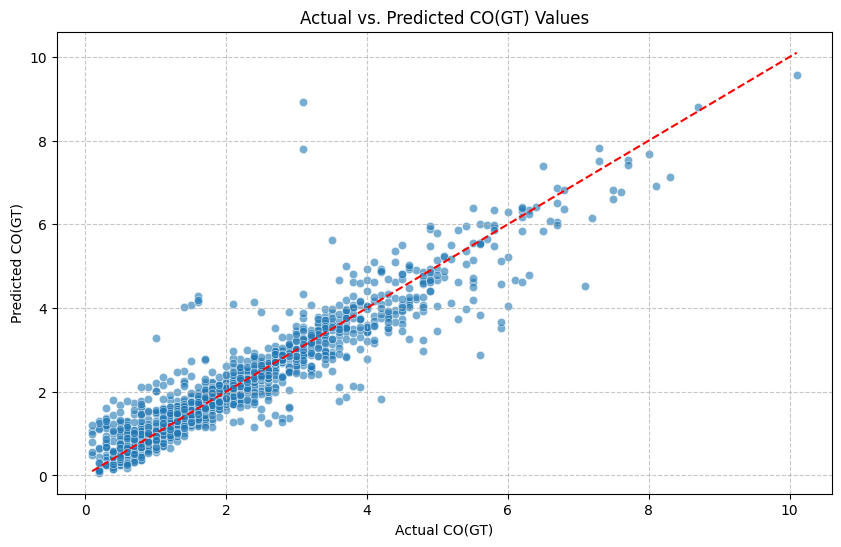

In [135]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--') # Red dashed line for perfect prediction
plt.title('Actual vs. Predicted CO(GT) Values')
plt.xlabel('Actual CO(GT)')
plt.ylabel('Predicted CO(GT)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()